# Matplotlib
Learn to make charts with short examples. Run cells from top to bottom. You need Matplotlib, NumPy, and pandas. All example data is included.

## Contents
1. Setup and Plot Basics
2. Line Charts
3. Styling, Labels, and Legends
4. Bar Charts
5. Pie Charts
6. Scatter Plots
7. Histograms
8. Subplots
9. Plotting pandas Data and Saving Figures
10. Practice

## 1. Setup and Plot Basics
Matplotlib makes charts. Import `matplotlib.pyplot` as `plt`. A Figure is the whole canvas; an Axes is one plot. `fig, ax = plt.subplots()` creates both.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Displaying charts in Jupyter
Run a plotting cell to see the chart below it. `plt.show()` displays it. Use a new figure for each example. `figsize` sets width and height in inches.

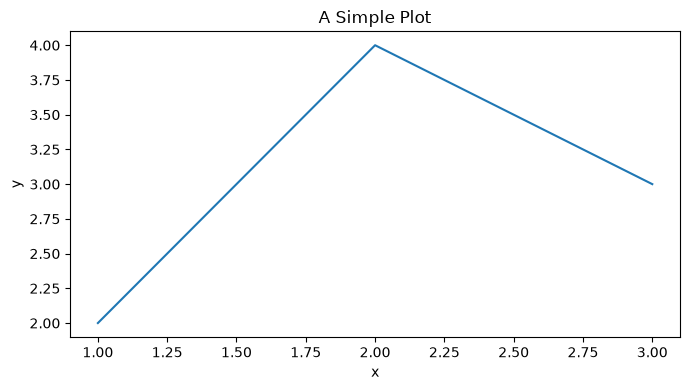

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([1, 2, 3], [2, 4, 3])
ax.set(title='A Simple Plot', xlabel='x', ylabel='y')
fig.tight_layout()
plt.show()

## 2. Line Charts
Line charts show changes across ordered values, such as years. Each x value needs a matching y value. Set year ticks to show whole years.

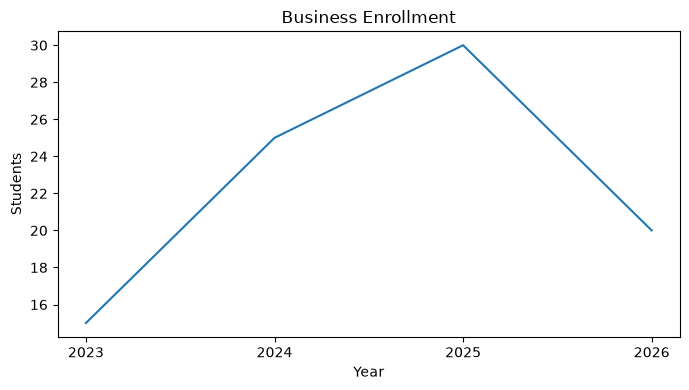

In [3]:
years = np.array([2023, 2024, 2025, 2026])
business = np.array([15, 25, 30, 20])
accounting = np.array([17, 23, 38, 50])
engineering = np.array([13, 15, 20, 30])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(years, business)
ax.set(title='Business Enrollment', xlabel='Year', ylabel='Students')
ax.set_xticks(years)
fig.tight_layout()
plt.show()

## 3. Styling, Labels, and Legends
Change line colors, styles, widths, and markers. Reuse settings with a dictionary and `**style`. Give each line a `label`, then call `legend()`.

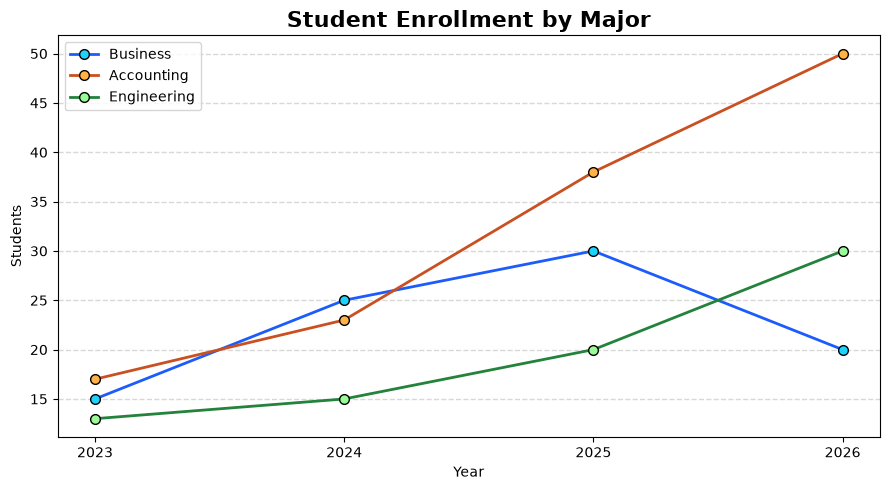

In [4]:
line_style = {'linestyle': '-', 'linewidth': 2, 'marker': 'o', 'markersize': 7, 'markeredgecolor': 'black'}
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(years, business, color='#1c5bfc', markerfacecolor='#1cd3fc', label='Business', **line_style)
ax.plot(years, accounting, color='#c95020', markerfacecolor='#ffb347', label='Accounting', **line_style)
ax.plot(years, engineering, color='#23823b', markerfacecolor='#98fb98', label='Engineering', **line_style)
ax.set_title('Student Enrollment by Major', fontsize=16, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Students')
ax.set_xticks(years)
ax.tick_params(axis='both', labelsize=10)
ax.grid(axis='y', linestyle='--', linewidth=1, color='gray', alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

### Setting tick intervals
Ticks are the labels along an axis. `np.arange(start, stop, step)` stops before `stop`. Choose an interval that is easy to read.

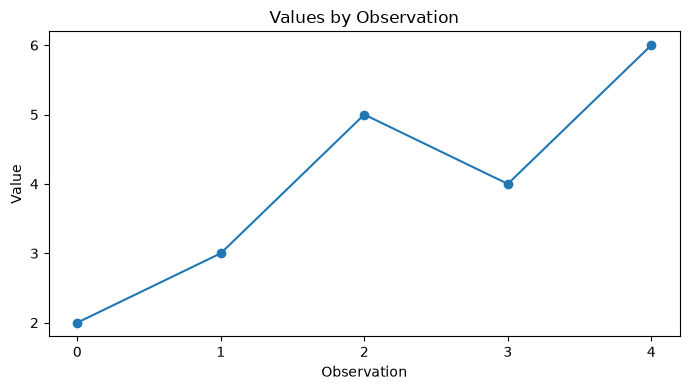

In [5]:
x = np.arange(5)
y = np.array([2, 3, 5, 4, 6])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, y, marker='o')
ax.set_xticks(x)
ax.set_yticks(np.arange(y.min(), y.max() + 1, 1))
ax.set(title='Values by Observation', xlabel='Observation', ylabel='Value')
fig.tight_layout()
plt.show()

## 4. Bar Charts
Bar charts compare categories. Use `bar()` for vertical bars and `barh()` for horizontal bars. Start the value axis at zero.

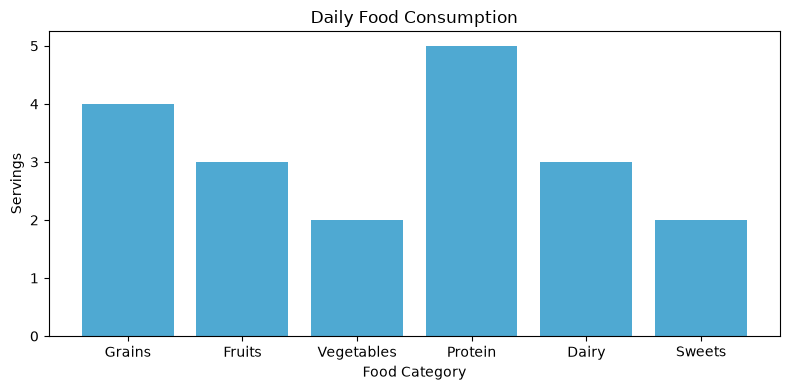

In [6]:
categories = ['Grains', 'Fruits', 'Vegetables', 'Protein', 'Dairy', 'Sweets']
quantities = np.array([4, 3, 2, 5, 3, 2])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(categories, quantities, color='#4fa9d2')
ax.set(title='Daily Food Consumption', xlabel='Food Category', ylabel='Servings')
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

## 5. Pie Charts
Pie charts show parts of a total. Use a few categories with nonnegative values and a total above zero. `autopct` adds percentages, `explode` moves a slice outward, and `startangle` rotates the chart.

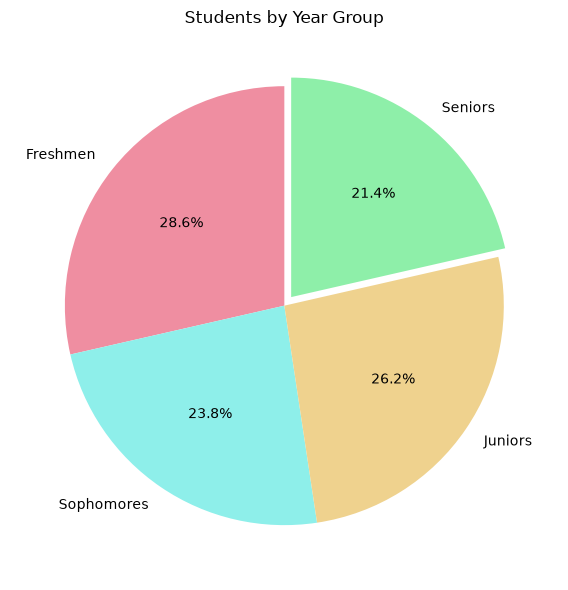

In [7]:
class_categories = ['Freshmen', 'Sophomores', 'Juniors', 'Seniors']
student_counts = np.array([300, 250, 275, 225])
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(student_counts, labels=class_categories, autopct='%1.1f%%',
       colors=['#ef8ea1', '#8eefea', '#efd28e', '#8eefa9'],
       explode=[0, 0, 0, 0.05], startangle=90)
ax.set_title('Students by Year Group')
ax.set_aspect('equal')
fig.tight_layout()
plt.show()

## 6. Scatter Plots
Scatter plots show pairs of numbers as points. Here, each point matches study hours with a score. `s` sets point size and `alpha` sets transparency. A pattern alone does not prove cause and effect.

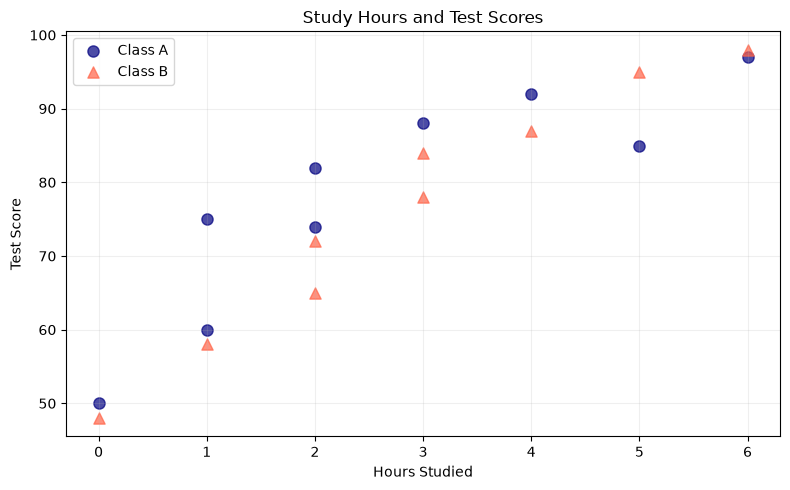

In [8]:
study_a = np.array([0, 1, 1, 2, 2, 3, 4, 5, 6])
scores_a = np.array([50, 60, 75, 74, 82, 88, 92, 85, 97])
study_b = np.array([0, 1, 2, 2, 3, 3, 4, 5, 6])
scores_b = np.array([48, 58, 65, 72, 78, 84, 87, 95, 98])
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(study_a, scores_a, s=65, color='navy', alpha=0.7, label='Class A')
ax.scatter(study_b, scores_b, s=65, color='tomato', marker='^', alpha=0.7, label='Class B')
ax.set(title='Study Hours and Test Scores', xlabel='Hours Studied', ylabel='Test Score')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 7. Histograms
Histograms group numbers into ranges called bins and count values in each bin. A seed repeats the same random example. `np.clip()` keeps scores between 0 and 100 by moving values outside that range to the nearest boundary.

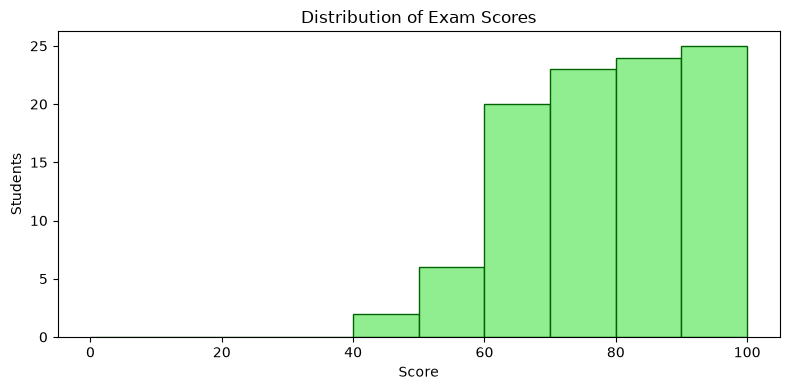

In [9]:
rng = np.random.default_rng(seed=2)
exam_scores = rng.normal(loc=80, scale=15, size=100)
exam_scores = np.clip(exam_scores, 0, 100)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(exam_scores, bins=np.arange(0, 101, 10), color='lightgreen', edgecolor='darkgreen')
ax.set(title='Distribution of Exam Scores', xlabel='Score', ylabel='Students')
fig.tight_layout()
plt.show()

## 8. Subplots
`plt.subplots(2, 2)` creates four plots. Select one with `axes[row, column]`. Add labels to each plot and use `tight_layout()` to improve spacing.

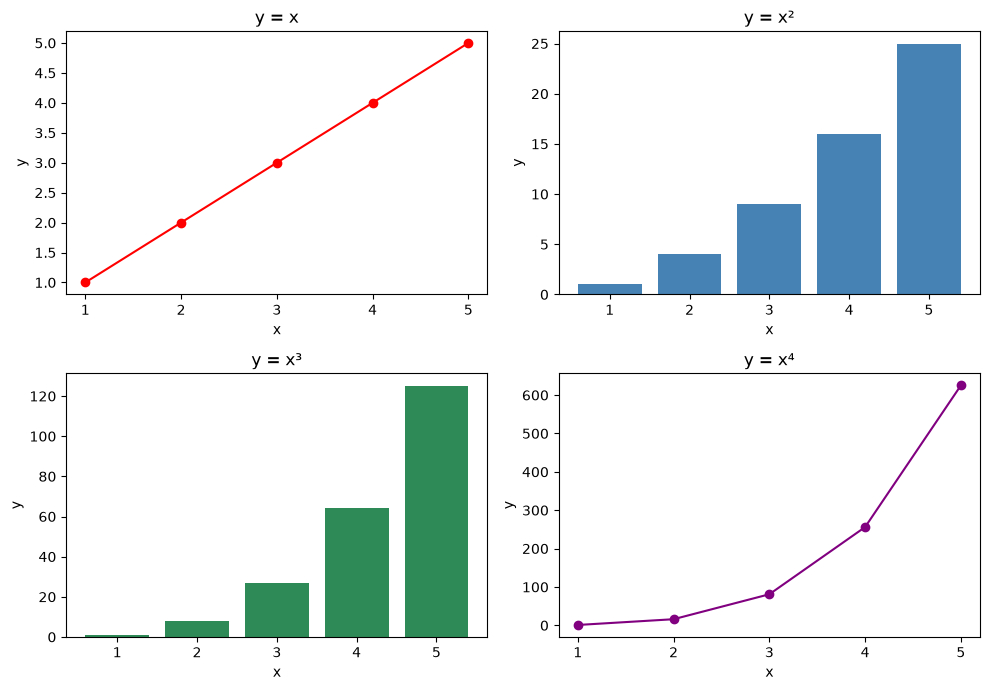

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
x = np.array([1, 2, 3, 4, 5])
axes[0, 0].plot(x, x, marker='o', color='red')
axes[0, 0].set_title('y = x')
axes[0, 1].bar(x, x ** 2, color='steelblue')
axes[0, 1].set_title('y = x²')
axes[1, 0].bar(x, x ** 3, color='seagreen')
axes[1, 0].set_title('y = x³')
axes[1, 1].plot(x, x ** 4, marker='o', color='purple')
axes[1, 1].set_title('y = x⁴')
for ax in axes.flat:
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_xticks(x)
fig.tight_layout()
plt.show()

## 9. Plotting pandas Data and Saving Figures
Use pandas to count categories, then plot the counts. `value_counts()` counts each type; `sort_values()` orders the counts. The example includes its data. You can also load your CSV with `pd.read_csv('pokemon_cleaned.csv')`.

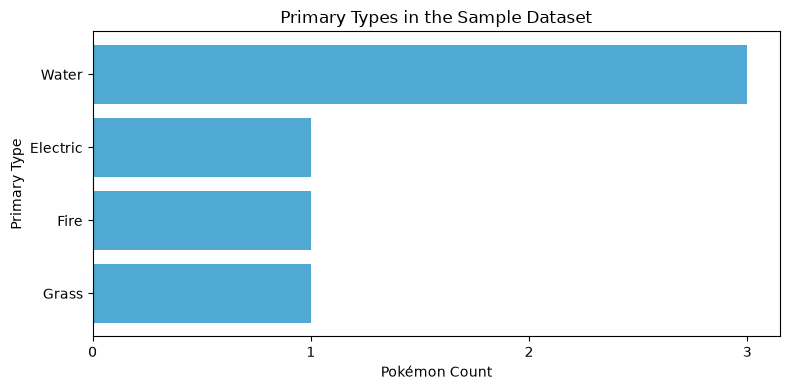

In [11]:
pokemon_df = pd.DataFrame({
    'Name': ['Bulbasaur', 'Charizard', 'Blastoise', 'Pikachu', 'Gyarados', 'Squirtle'],
    'Type1': ['Grass', 'Fire', 'Water', 'Electric', 'Water', 'Water'],
})
type_counts = pokemon_df['Type1'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(type_counts.index, type_counts.values, color='#4fa9d2')
ax.set(title='Primary Types in the Sample Dataset', xlabel='Pokémon Count', ylabel='Primary Type')
ax.set_xticks(np.arange(0, type_counts.max() + 1))
fig.tight_layout()
plt.show()

### Saving a figure
`fig.savefig()` saves a chart. `dpi` controls image resolution, and `bbox_inches='tight'` keeps labels inside the saved image. Save before `plt.show()`, or keep the `fig` variable to save it later.

In [12]:
# Uncomment to export the preceding figure:
# fig.savefig('pokemon_type_counts.png', dpi=150, bbox_inches='tight')

## 10. Practice
1. Plot a line chart for four years of sales. Add a title and axis labels.
2. Add a second line, distinct markers, and a legend.
3. Set integer year ticks and add a light horizontal grid.
4. Compare four categories with a bar chart, then try `barh()`.
5. Create a pie chart from values that form one total.
6. Plot study hours against scores using a scatter plot.
7. Compare histograms using different bin counts.
8. Create a 2-by-2 figure with a different chart in each subplot.
9. Count categories in a DataFrame and plot the counts.
10. Save one figure as a PNG using `fig.savefig()`.

In [13]:
# Write your practice code here
